# Potential outliers: feature boxplots and monthly consumption

This notebook combines both requested analyses. The code has been run and the outputs are included. Put `dataset_mansion.csv` beside the notebook or update the path below.

**No observations are removed, replaced or imputed.** Missing values are omitted only from each plotted distribution and its calculations. Constant numeric columns are excluded from these plots, while remaining in the original dataframe.

In [1]:
from pathlib import Path
import math
import calendar
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

path = Path('dataset_mansion.csv')
if not path.exists():
    path = Path('upload/dataset_mansion.csv')

df = pd.read_csv(path, index_col=0)
df['Consumption'] = pd.to_numeric(
    df['Consumption'].astype('string').str.replace(',', '.', regex=False),
    errors='raise'
)
# Documentation specifies UTC timestamps.
df['MTime'] = pd.to_datetime(df['MTime'], utc=True, errors='raise')
assert df['MTime'].notna().all(), 'Investigate missing timestamps first.'
assert not df['MTime'].duplicated().any(), 'Investigate duplicate timestamps first.'
df = df.set_index('MTime').sort_index()

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Boxplot for each varying numeric feature

Each feature has its own scale. The middle line is the median, and the box spans the middle 50% of observed values (Q1 to Q3). Whiskers extend to the most extreme observations within **1.5 × IQR** of the box, where IQR = Q3 − Q1. Dots beyond the whiskers are **potential outliers**, not confirmed errors.

The summary table counts values strictly below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. Its percentages use each column's non-missing observations.

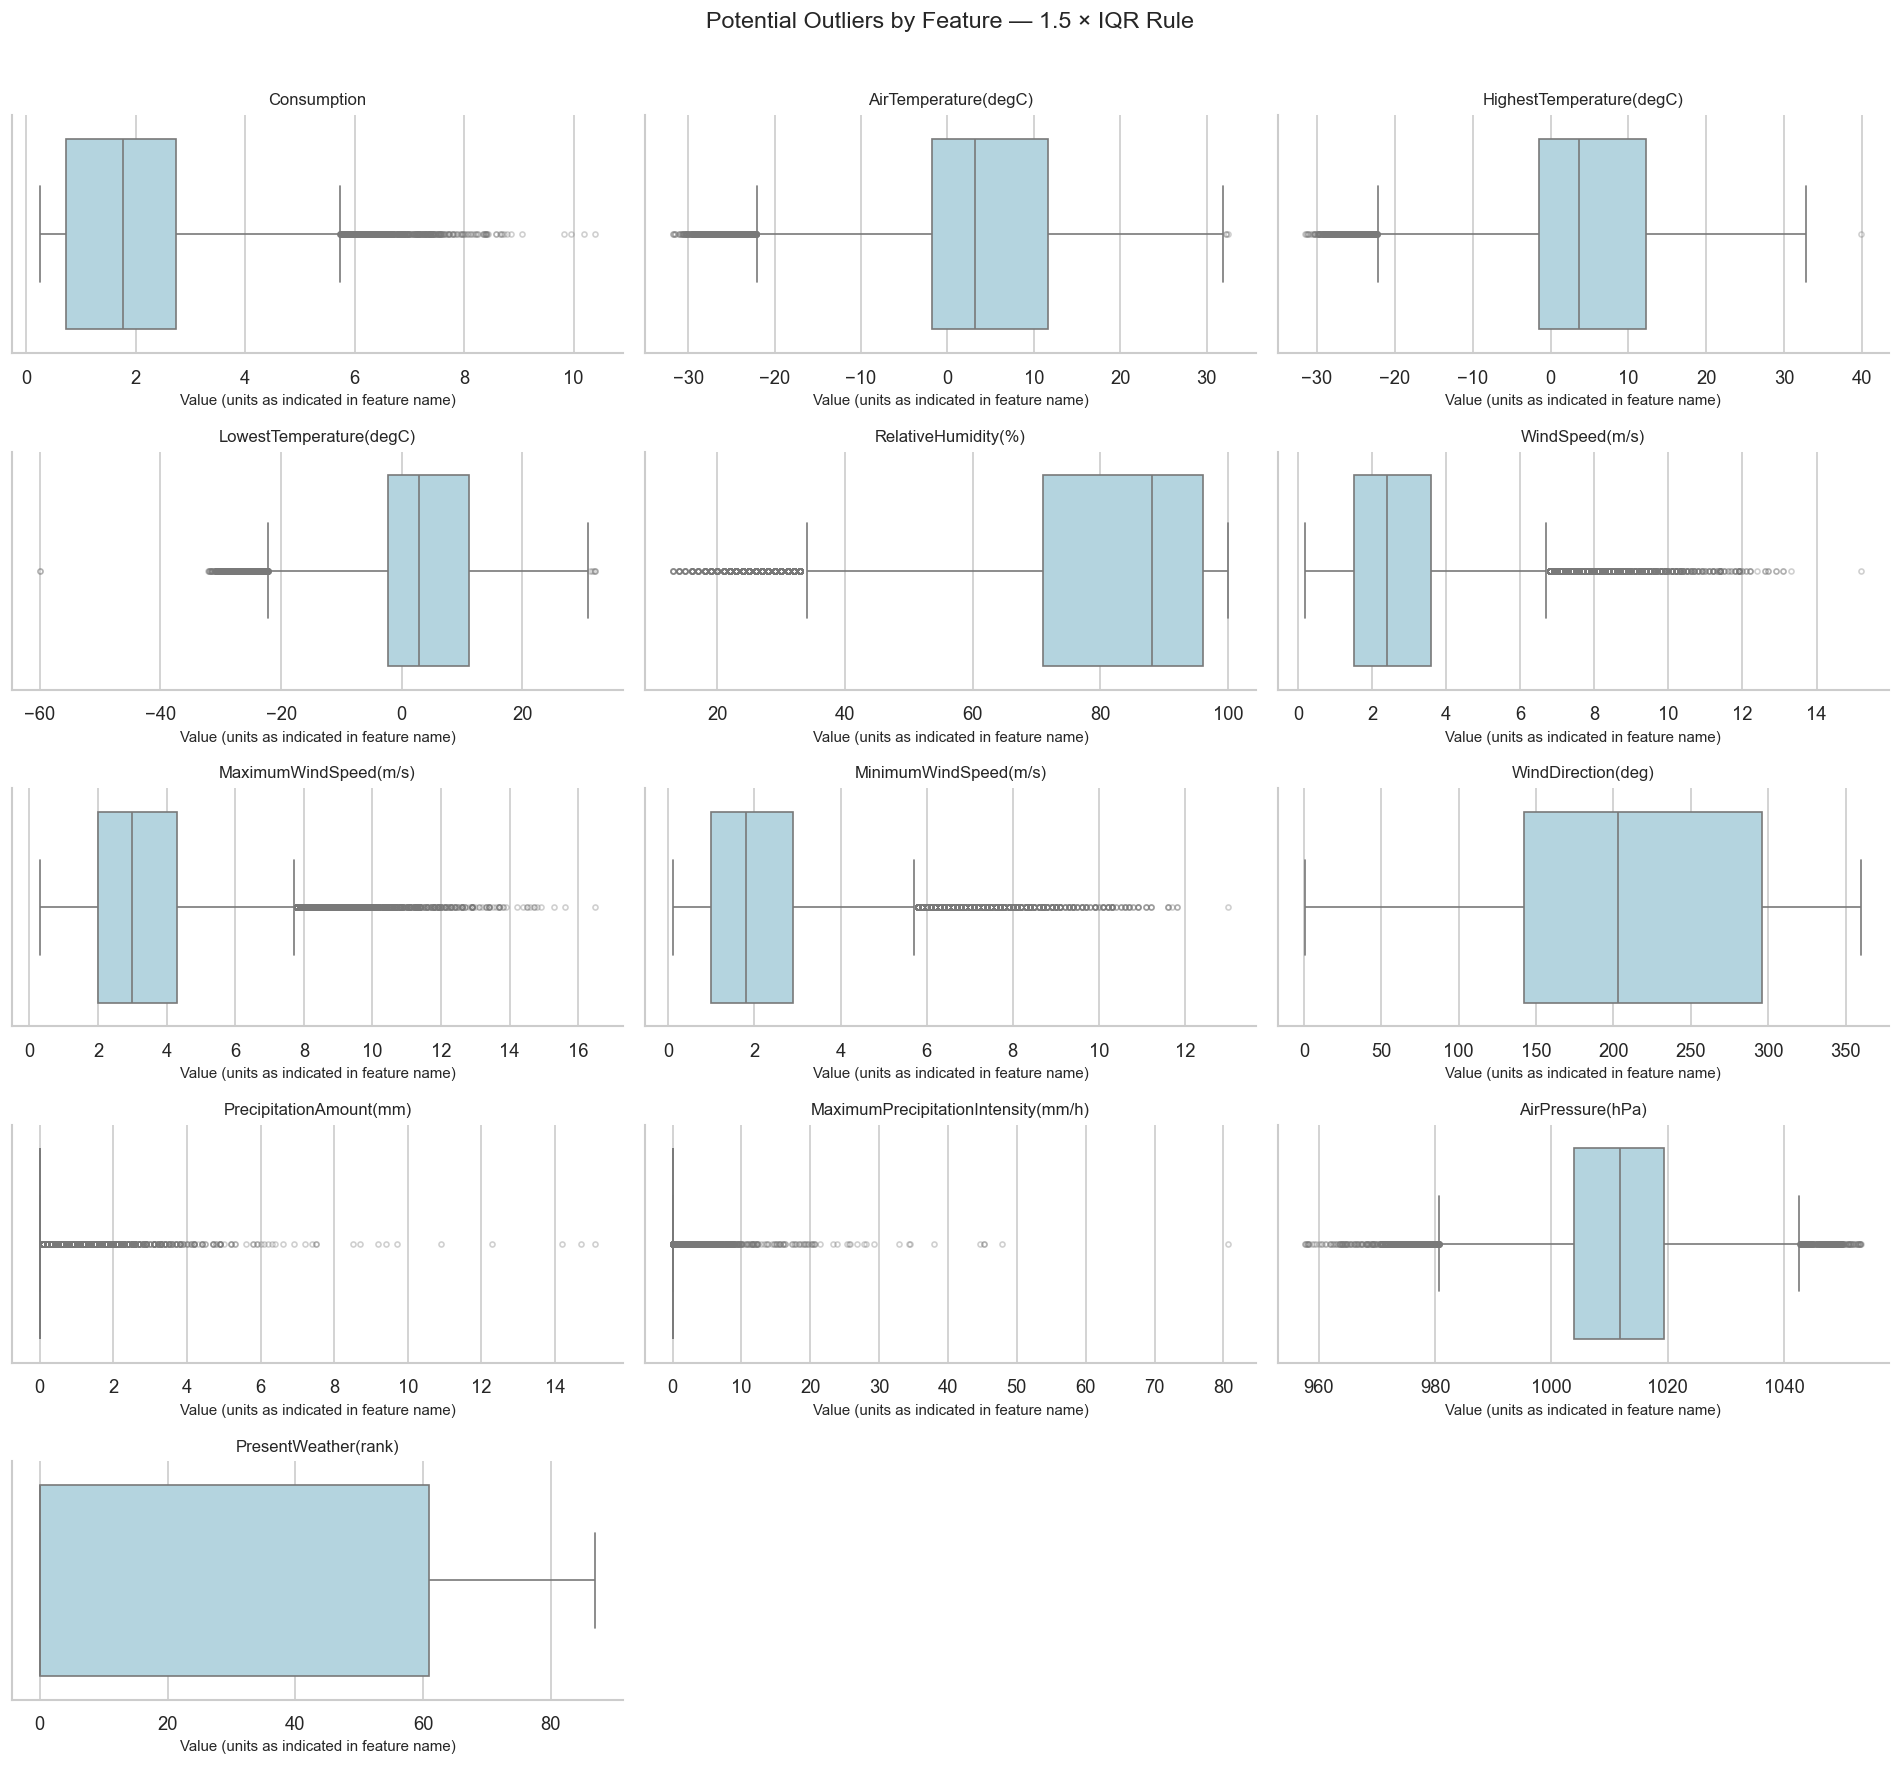

,Observed values,IQR,Lower fence,Upper fence,Flagged values,Flagged (%)
Feature,,,,,,
MaximumPrecipitationIntensity(mm/h),55910,0.0,0.00,0.00,7965,14.246
PrecipitationAmount(mm),55928,0.0,0.00,0.00,7542,13.485
RelativeHumidity(%),55942,25.0,33.50,133.50,1850,3.307
MaximumWindSpeed(m/s),55490,2.3,-1.45,7.75,1741,3.138
MinimumWindSpeed(m/s),55490,1.9,-1.85,5.75,1739,3.134
WindSpeed(m/s),55613,2.1,-1.65,6.75,1659,2.983
AirPressure(hPa),56021,15.5,980.65,1042.65,943,1.683
Consumption,56231,2.0,-2.27,5.73,744,1.323
LowestTemperature(degC),56028,13.3,-22.15,31.05,558,0.996


In [2]:
numeric_df = df.select_dtypes(include='number')
numeric_df = numeric_df.loc[:, numeric_df.nunique(dropna=True) > 1]
assert len(numeric_df.columns) > 0, 'No varying numeric features to plot.'

ncols = 3
nrows = math.ceil(len(numeric_df.columns) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows), squeeze=False)
summary = []

for ax, col in zip(axes.flat, numeric_df.columns):
    values = numeric_df[col].dropna()
    sns.boxplot(
        x=values, ax=ax, color='lightblue', whis=1.5,
        flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.35}
    )
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flagged = (values < lower) | (values > upper)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('Value (units as indicated in feature name)', fontsize=9)
    ax.set_ylabel('')
    summary.append({
        'Feature': col,
        'Observed values': len(values),
        'IQR': iqr,
        'Lower fence': lower,
        'Upper fence': upper,
        'Flagged values': int(flagged.sum()),
        'Flagged (%)': flagged.mean() * 100
    })

for ax in list(axes.flat)[len(numeric_df.columns):]:
    ax.set_visible(False)
fig.suptitle('Potential Outliers by Feature — 1.5 × IQR Rule', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

outlier_summary = pd.DataFrame(summary).set_index('Feature').sort_values('Flagged (%)', ascending=False)
display(outlier_summary.round(3))

**Interpret carefully:**

- High consumption can reflect normal winter heating or appliance use.
- Precipitation is strongly skewed and often zero. If IQR = 0, the two fences coincide and any different value is flagged. This does not make rain an error.
- Wind direction is circular (359° is near 1°); an ordinary boxplot does not respect that geometry.
- Weather rank needs its coding definition before treating its numeric distances as meaningful. It also covers a different subset of timestamps because of missing values.
- Flags across columns may refer to the same rows, so their counts should not be added to obtain a number of unique outlier rows.

## 2. Consumption boxplots by month

Each box contains **hourly observations for that calendar month, pooled across the available years**. Every month gets its own quartiles and fences, allowing comparison with the season rather than with the full-year distribution.

Timestamps are converted from UTC to **Europe/Helsinki**, including daylight saving. The record spans January 2016–May 2022 in local time: January–May contain seven years, and June–December contain six. The plot is descriptive, with unequal sample sizes. The source does not specify the consumption unit, so the axis uses “source units.”

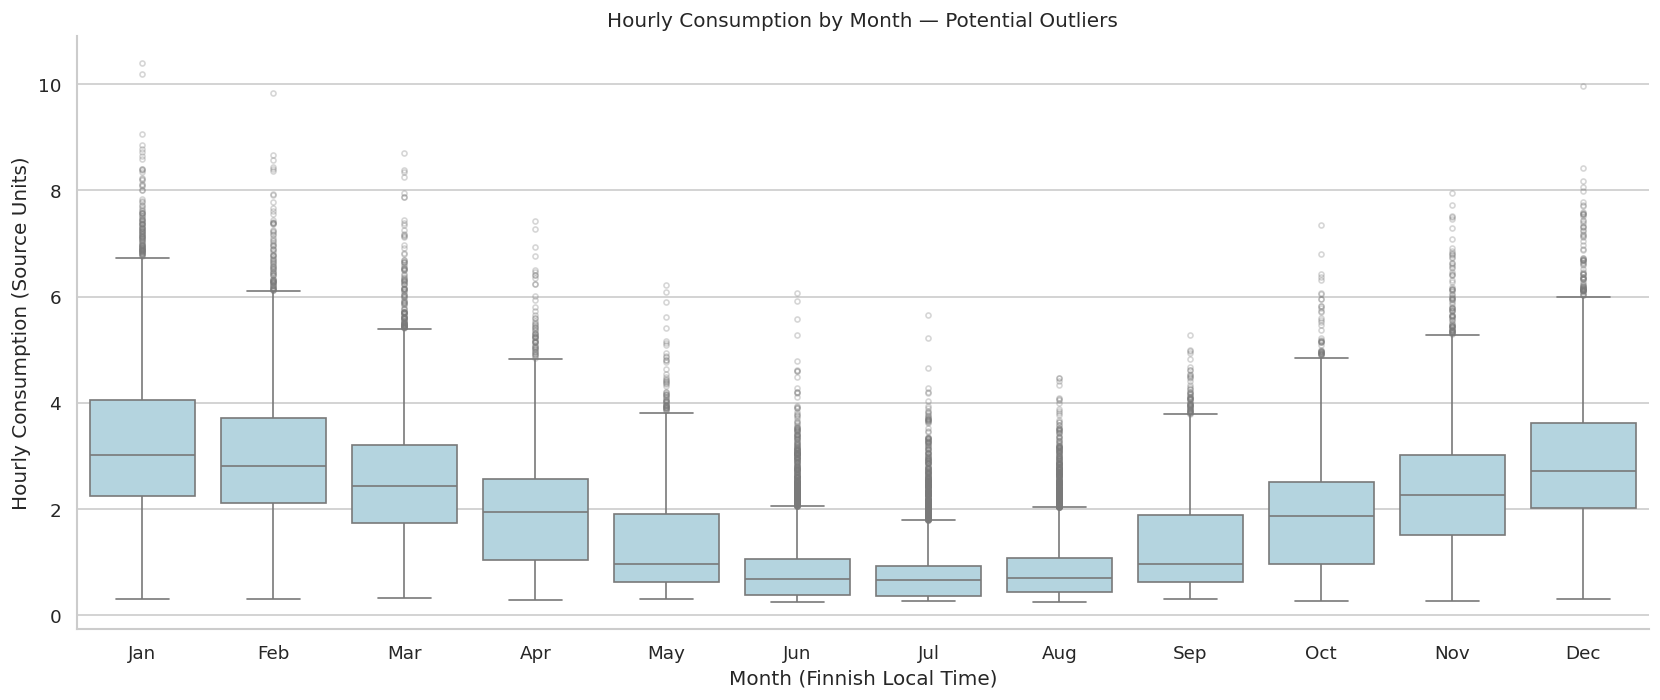

In [3]:
monthly_data = df[['Consumption']].copy()
index = pd.to_datetime(monthly_data.index)
if index.tz is None:
    index = index.tz_localize('UTC')
monthly_data.index = index.tz_convert('Europe/Helsinki')
monthly_data['Month'] = monthly_data.index.month

plt.figure(figsize=(14, 6))
sns.boxplot(
    data=monthly_data, x='Month', y='Consumption',
    order=range(1, 13), color='lightblue', whis=1.5,
    flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.3}
)
plt.xticks(range(12), list(calendar.month_abbr)[1:])
plt.title('Hourly Consumption by Month — Potential Outliers')
plt.xlabel('Month (Finnish Local Time)')
plt.ylabel('Hourly Consumption (Source Units)')
plt.tight_layout()
plt.show()

## How to use these results

Use the first figure to locate features with unusual tails and the monthly figure to understand consumption in seasonal context. A dot outside a monthly box is unusual under that month's IQR rule, but can still be valid. Month pooling does not account for hour-of-day patterns or changes between years.

Inspect flagged observations in their surrounding time window and alongside weather or household context before deciding what to do. **These charts flag candidates for investigation; they do not justify automatic removal.**